# RSSC biovar model evaluation

In [ ]:
from __future__ import annotations

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    auc,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    matthews_corrcoef,
    precision_recall_curve,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.preprocessing import LabelEncoder, label_binarize


RANDOM_STATE = 42
N_SPLITS = 10
N_REPEATS = 3
DATA_PATH = Path(
    os.environ.get(
        "RSSC_TRAINING_DATA",
        r"E:\Data\Ralstonia\newdata\final_knumber\code_data\delete_outlier\training_dataset.csv",
    )
)

plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams["font.size"] = 12
plt.rcParams["svg.fonttype"] = "none"


def load_training_data(path: Path):
    """Load the KO feature matrix and the three phenotype targets."""
    data = pd.read_csv(path)
    data1 = data.iloc[:, 1:].astype(int)

    # The final four columns are metadata/labels
    X = data1.iloc[:, :-4]
    y_disaccharide = data1["disaccharide_metabolism"].to_numpy()
    y_hexitol = data1["hexitol_metabolism"].to_numpy()

    encoder = LabelEncoder()
    y_biovar = encoder.fit_transform(data1["biovar"])
    biovar_labels = encoder.classes_.astype(str).tolist()

    print(f"Samples: {len(X)}; KO features: {X.shape[1]}")
    print(f"Biovar labels: {biovar_labels}")
    return X, y_disaccharide, y_hexitol, y_biovar, biovar_labels


def combine_predictions(disaccharide_pred, hexitol_pred):
    """Encode the two binary predictions as biovar classes 0, 1, 2, 3."""
    d = np.asarray(disaccharide_pred, dtype=int)
    h = np.asarray(hexitol_pred, dtype=int)
    if d.shape != h.shape:
        raise ValueError("Disaccharide and hexitol predictions must have the same shape.")
    combined = np.full(d.shape, -1, dtype=int)
    combined[(d == 0) & (h == 0)] = 0
    combined[(d == 1) & (h == 0)] = 1
    combined[(d == 1) & (h == 1)] = 2
    combined[(d == 0) & (h == 1)] = 3
    if np.any(combined < 0):
        raise ValueError("Binary predictions must contain only 0 and 1.")
    return combined


def combine_probabilities(disaccharide_prob, hexitol_prob):
    """Combine independent binary probabilities into four biovar probabilities."""
    d = np.asarray(disaccharide_prob)
    h = np.asarray(hexitol_prob)
    return np.column_stack(((1 - d) * (1 - h), d * (1 - h), d * h, (1 - d) * h))


def make_models():
    """Create the four model/trait combinations used in the fixed-seed audit."""
    return {
        "Disaccharide (XGBRFClassifier)": (xgb.XGBRFClassifier(random_state=RANDOM_STATE), "disaccharide"),
        "Hexitol (XGBClassifier)": (xgb.XGBClassifier(random_state=RANDOM_STATE), "hexitol"),
        "Disaccharide (XGBClassifier)": (xgb.XGBClassifier(random_state=RANDOM_STATE), "disaccharide"),
        "Hexitol (XGBRFClassifier)": (xgb.XGBRFClassifier(random_state=RANDOM_STATE), "hexitol"),
    }


def specificity_score(y_true, y_pred, average="binary"):
    """Calculate specificity, using a macro one-vs-rest value for multiclass data."""
    cm = confusion_matrix(y_true, y_pred)
    if cm.shape == (2, 2) and average == "binary":
        tn, fp, _, _ = cm.ravel()
        return tn / (tn + fp) if (tn + fp) else np.nan

    total = cm.sum()
    values = []
    for class_index in range(len(cm)):
        tp = cm[class_index, class_index]
        fp = cm[:, class_index].sum() - tp
        fn = cm[class_index, :].sum() - tp
        tn = total - tp - fp - fn
        values.append(tn / (tn + fp) if (tn + fp) else np.nan)
    return float(np.nanmean(values))


def metric_summary(name, y_true, y_pred, y_prob):
    """Return the metrics reported by the fixed-seed evaluation."""
    y_prob = np.asarray(y_prob)
    n_classes = y_prob.shape[1] if y_prob.ndim == 2 else 2
    average = "binary" if n_classes == 2 else "macro"
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average=average, zero_division=0
    )
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision,
        "Recall / sensitivity": recall,
        "F1 score": f1,
        "Specificity": specificity_score(y_true, y_pred, average),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
    }
    if n_classes == 2:
        row["ROC AUC"] = roc_auc_score(y_true, y_prob)
        row["Average precision"] = average_precision_score(y_true, y_prob)
        row["Brier score"] = brier_score_loss(y_true, y_prob)
    else:
        y_onehot = label_binarize(y_true, classes=np.arange(n_classes))
        row["ROC AUC"] = roc_auc_score(y_onehot, y_prob, average="macro", multi_class="ovr")
        row["Average precision"] = average_precision_score(y_onehot, y_prob, average="macro")
        row["Brier score"] = np.nan
    return row


def run_repeated_evaluation(X, y_disaccharide, y_hexitol, y_biovar, n_repeats=N_REPEATS):
    """Train all four binary models and the selected biovar combination."""
    targets = {"disaccharide": y_disaccharide, "hexitol": y_hexitol}
    splitter = RepeatedStratifiedKFold(
        n_splits=N_SPLITS, n_repeats=n_repeats, random_state=RANDOM_STATE
    )
    records = {
        "Disaccharide (XGBRFClassifier)": [],
        "Hexitol (XGBClassifier)": [],
        "Disaccharide (XGBClassifier)": [],
        "Hexitol (XGBRFClassifier)": [],
        "Biovar (combined)": [],
    }

    for fold, (train_idx, test_idx) in enumerate(splitter.split(X, y_disaccharide), start=1):
        models = make_models()
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        for estimator, target_name in models.values():
            estimator.fit(X_train, targets[target_name][train_idx])

        predictions = {}
        for name, (estimator, target_name) in models.items():
            target = targets[target_name]
            predictions[name] = (
                target[test_idx],
                estimator.predict(X_test),
                estimator.predict_proba(X_test)[:, 1],
            )
            records[name].append(predictions[name])

        dis_estimator = models["Disaccharide (XGBClassifier)"][0]
        hex_estimator = models["Hexitol (XGBRFClassifier)"][0]
        dis_prob = dis_estimator.predict_proba(X_test)[:, 1]
        hex_prob = hex_estimator.predict_proba(X_test)[:, 1]
        records["Biovar (combined)"].append(
            (
                y_biovar[test_idx],
                combine_predictions(dis_estimator.predict(X_test), hex_estimator.predict(X_test)),
                combine_probabilities(dis_prob, hex_prob),
            )
        )
        if fold % N_SPLITS == 0:
            print(f"Completed fold {fold}/{N_SPLITS * n_repeats}")

    summary_rows = []
    for name, folds in records.items():
        fold_table = pd.DataFrame(
            [metric_summary(name, y_true, y_pred, y_prob) for y_true, y_pred, y_prob in folds]
        )
        means = fold_table.mean(numeric_only=True)
        row = {"Model": name, **means.to_dict()}
        row["Accuracy SD"] = fold_table["Accuracy"].std(ddof=0)
        row["Balanced accuracy SD"] = fold_table["Balanced accuracy"].std(ddof=0)
        row["n_test_folds"] = len(folds)
        summary_rows.append(row)
    return pd.DataFrame(summary_rows), records


def run_plot_evaluation(X, y_disaccharide, y_hexitol, y_biovar):
    splitter = RepeatedStratifiedKFold(
        n_splits=N_SPLITS, n_repeats=1, random_state=RANDOM_STATE
    )
    records = {"Disaccharide": [], "Hexitol": [], "Biovar": []}
    for train_idx, test_idx in splitter.split(X, y_disaccharide):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        dis_estimator = xgb.XGBClassifier(random_state=RANDOM_STATE)
        hex_estimator = xgb.XGBRFClassifier(random_state=RANDOM_STATE)
        dis_estimator.fit(X_train, y_disaccharide[train_idx])
        hex_estimator.fit(X_train, y_hexitol[train_idx])

        dis_pred = dis_estimator.predict(X_test)
        hex_pred = hex_estimator.predict(X_test)
        dis_prob = dis_estimator.predict_proba(X_test)[:, 1]
        hex_prob = hex_estimator.predict_proba(X_test)[:, 1]
        records["Disaccharide"].append((y_disaccharide[test_idx], dis_pred, dis_prob))
        records["Hexitol"].append((y_hexitol[test_idx], hex_pred, hex_prob))
        records["Biovar"].append(
            (
                y_biovar[test_idx],
                combine_predictions(dis_pred, hex_pred),
                combine_probabilities(dis_prob, hex_prob),
            )
        )

    return {
        name: {
            "folds": folds,
            "pooled": (
                np.concatenate([item[0] for item in folds]),
                np.concatenate([item[1] for item in folds]),
                np.concatenate([item[2] for item in folds]),
            ),
        }
        for name, folds in records.items()
    }


def plot_roc_and_confusion(plot_results, biovar_labels):
    task_order = ["Hexitol", "Disaccharide", "Biovar"]
    task_titles = {
        "Hexitol": "Hexitols",
        "Disaccharide": "Disaccharides",
        "Biovar": "Biovar",
    }
    confusion_labels = {
        "Disaccharide": ["0", "1"],
        "Hexitol": ["0", "1"],
        "Biovar": ["1", "2", "3", "4"],
    }
    confusion_axis_labels = {
        "Hexitol": ("Predicted Hexitols Metabolism", "True Hexitols Metabolism"),
        "Disaccharide": ("Predicted Disaccharides Metabolism", "True Disaccharides Metabolism"),
        "Biovar": ("Predicted Biovar", "True Biovar"),
    }

    fig, axes = plt.subplots(3, 2, figsize=(10, 14))
    mean_fpr = np.linspace(0, 1, 100)
    for row, name in enumerate(task_order):
        tprs, aucs = [], []
        for fold, (y_true, y_pred, y_prob) in enumerate(plot_results[name]["folds"]):
            if name == "Biovar":
                y_onehot = label_binarize(y_true, classes=np.arange(4))
                fpr, tpr, _ = roc_curve(y_onehot.ravel(), y_prob.ravel())
            else:
                fpr, tpr, _ = roc_curve(y_true, y_prob)
            roc_auc = auc(fpr, tpr)
            axes[row, 0].plot(fpr, tpr, alpha=0.3, lw=1)
            interp_tpr = np.interp(mean_fpr, fpr, tpr)
            interp_tpr[0] = 0.0
            tprs.append(interp_tpr)
            aucs.append(roc_auc)

        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        mean_auc = auc(mean_fpr, mean_tpr)
        std_tpr = np.std(tprs, axis=0)
        axes[row, 0].plot(
            mean_fpr,
            mean_tpr,
            color="b",
            lw=2,
            alpha=0.8,
            label=f"Mean ROC (AUC = {mean_auc:.2f})",
        )
        axes[row, 0].fill_between(
            mean_fpr,
            np.maximum(mean_tpr - std_tpr, 0),
            np.minimum(mean_tpr + std_tpr, 1),
            color="grey",
            alpha=0.2,
            label="± 1 std. dev.",
        )
        axes[row, 0].plot(
            [0, 1],
            [0, 1],
            color="red",
            linestyle="--",
            lw=1,
            label="Chance",
        )
        axes[row, 0].set(
            xlabel="False positive rate",
            ylabel="True positive rate",
            title=task_titles[name],
            xlim=(-0.01, 1.01),
            ylim=(-0.01, 1.01),
        )
        axes[row, 0].set_aspect("equal")
        handles, labels = axes[row, 0].get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        legend_order = ["Chance", f"Mean ROC (AUC = {mean_auc:.2f})", "± 1 std. dev."]
        axes[row, 0].legend(
            [by_label[label] for label in legend_order],
            legend_order,
            loc="lower right",
            fontsize=8,
            frameon=True,
        )

        y_true, y_pred, _ = plot_results[name]["pooled"]
        ConfusionMatrixDisplay.from_predictions(
            y_true,
            y_pred,
            display_labels=confusion_labels[name],
            cmap=plt.cm.Blues,
            ax=axes[row, 1],
        )
        xlabel, ylabel = confusion_axis_labels[name]
        axes[row, 1].set_xlabel(xlabel)
        axes[row, 1].set_ylabel(ylabel)
        axes[row, 1].set_title(task_titles[name])

    plt.tight_layout()
    plt.show()


def plot_precision_recall(plot_results, biovar_labels):
    fig_pr, pr_axes = plt.subplots(1, 3, figsize=(16, 5.2), constrained_layout=True)
    for ax, name, label in [
        (pr_axes[0], "Hexitol", "Hexitols"),
        (pr_axes[1], "Disaccharide", "Disaccharides"),
    ]:
        y_true, _, y_prob = plot_results[name]["pooled"]
        PrecisionRecallDisplay.from_predictions(y_true, y_prob, name=label, ax=ax, lw=2)
        ax.axhline(y_true.mean(), color="black", ls="--", lw=1, label=f"Prevalence = {y_true.mean():.3f}")
        ax.set(title=f"{label} Precision-Recall", xlim=(0, 1), ylim=(0, 1.05), xlabel="Recall", ylabel="Precision")
        ax.legend(loc="lower left", frameon=False)

    y_true, _, y_prob = plot_results["Biovar"]["pooled"]
    y_onehot = label_binarize(y_true, classes=np.arange(4))
    for i, label in enumerate(biovar_labels):
        PrecisionRecallDisplay.from_predictions(
            y_onehot[:, i], y_prob[:, i], name=f"Biovar {label}", ax=pr_axes[2], lw=2
        )
    pr_axes[2].set(title="Biovar Precision-Recall (one-vs-rest)", xlim=(0, 1), ylim=(0, 1.05), xlabel="Recall", ylabel="Precision")
    pr_axes[2].legend(loc="lower left", fontsize=9, frameon=False)
    plt.show()



X, y_disaccharide, y_hexitol, y_biovar, biovar_labels = load_training_data(DATA_PATH)


Samples: 250; KO features: 2566
Biovar labels: ['1', '2', '3', '4']


In [11]:
# Numerical evaluation: repeated 10-fold CV (3 repeats).
summary, repeated_records = run_repeated_evaluation(
    X, y_disaccharide, y_hexitol, y_biovar, n_repeats=N_REPEATS
)
print("\nFold-averaged metrics (30 test folds):")
print(summary.to_string(index=False, float_format=lambda value: f"{value:.8g}"))

for name, folds in repeated_records.items():
    y_true = np.concatenate([item[0] for item in folds])
    y_pred = np.concatenate([item[1] for item in folds])
    labels = biovar_labels if name == "Biovar (combined)" else ["0", "1"]
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=labels, zero_division=0))


Completed fold 10/30
Completed fold 20/30
Completed fold 30/30

Fold-averaged metrics (30 test folds):
                         Model   Accuracy  Balanced accuracy  Precision  Recall / sensitivity   F1 score  Specificity        MCC  Cohen's kappa    ROC AUC  Average precision  Brier score  Accuracy SD  Balanced accuracy SD  n_test_folds
Disaccharide (XGBRFClassifier)      0.916         0.90916667 0.93512765            0.93611111 0.93385776   0.88222222 0.82288253     0.81738878 0.96490741         0.98273523  0.068811156  0.054990908           0.069946656            30
       Hexitol (XGBClassifier)      0.976         0.97535587 0.97751166            0.96616402 0.97003743   0.98454772 0.95186284     0.94958917 0.98096342         0.97673221  0.020637692  0.035175749           0.037583676            30
  Disaccharide (XGBClassifier) 0.93733333         0.93775463 0.96677116               0.93625 0.94961989   0.93925926 0.87189503     0.86594902 0.96224074         0.97837689  0.056286136  0

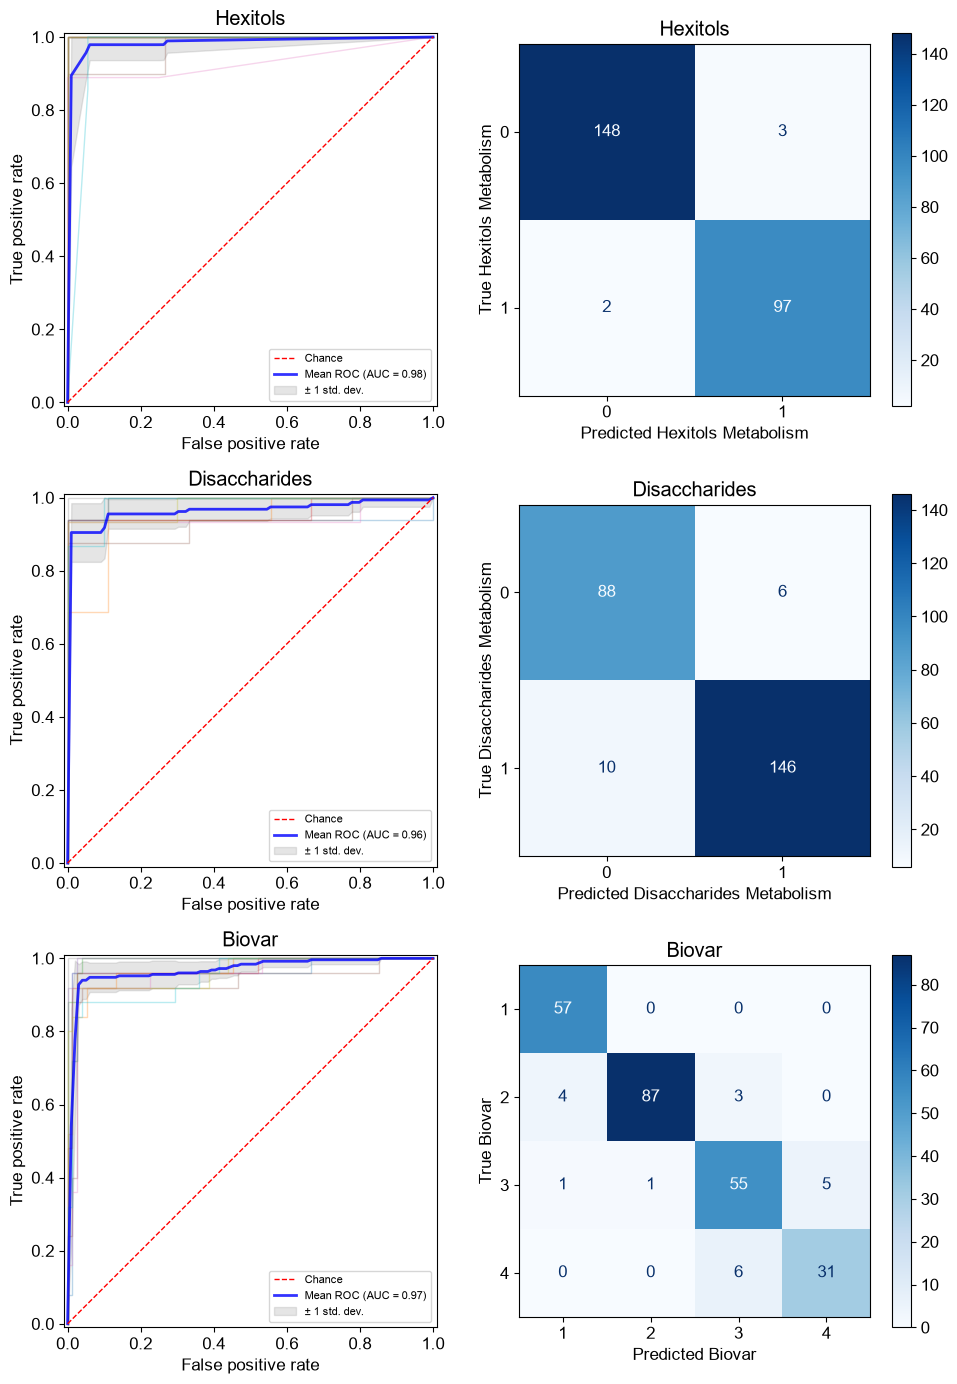

In [12]:
# ROC curves and raw-count confusion matrices (old 3x2 layout).
plot_results = run_plot_evaluation(X, y_disaccharide, y_hexitol, y_biovar)
plot_roc_and_confusion(plot_results, biovar_labels)


d:\APP\Programme\Anaconda3\envs\graduation2_xgb\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
d:\APP\Programme\Anaconda3\envs\graduation2_xgb\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
d:\APP\Programme\Anaconda3\envs\graduation2_xgb\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
d:\APP\Programme\Anaconda3\envs\graduation2_xgb\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionar

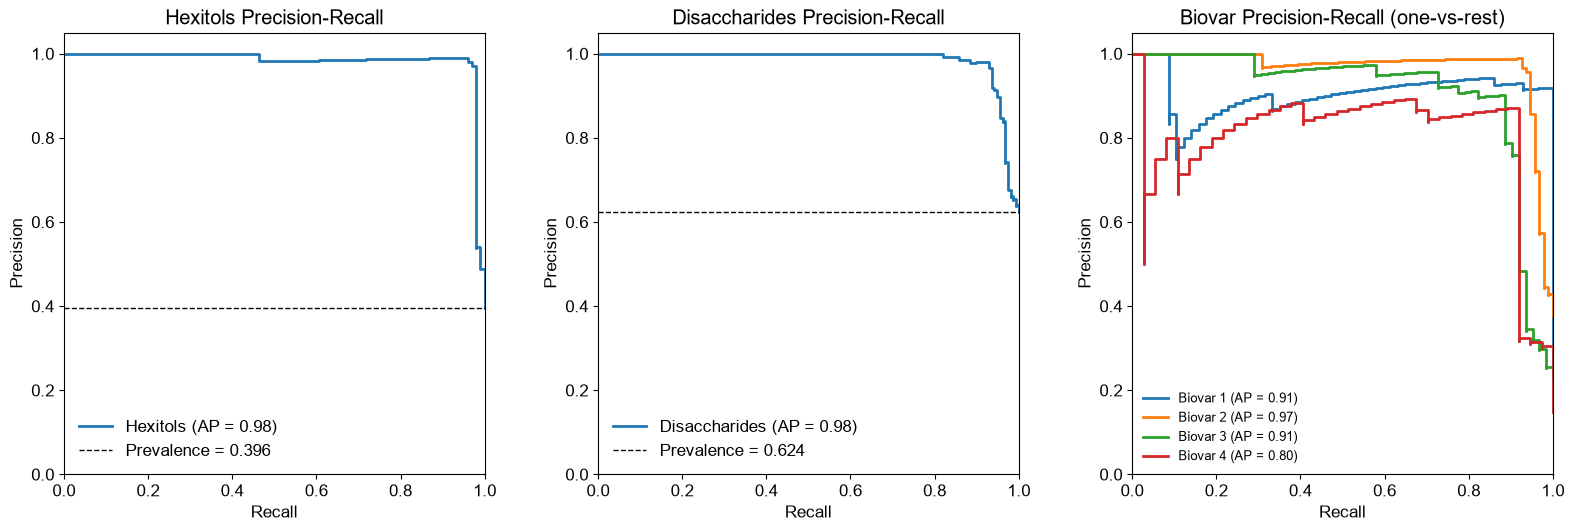

In [13]:
# Precision-recall curves (old separate 1x3 layout).
plot_precision_recall(plot_results, biovar_labels)
